# <b>Diffusion-TS conditional forecasting for liquidation events</b>

## Disclaimer

This notebook contains quite a lot of technical code that has not been factored out into separate `.py` files. The main goal of the notebook is not to build a final production pipeline, but to check how correctly a conditional diffusion model is able to generate future liquidation events given known past history.

For a quick read, you can first look at the plots and then jump to the `Executive summary` at the end of the notebook.

---

## Problem statement

The main question is how to correctly use diffusion models in the toxic-flow filtering task, and what additional information they can provide.

This notebook tests a conditional forecasting setup. The model receives a known history of liquidation events and must generate a distribution of future liquidation events:

$$
P(X_{t:t+k} \mid X_{0:t}).
$$

Each liquidation event is described by two features:

$$
X_i =
(\log(1 + \Delta t_i),\ \log(1 + \text{dollar amount}_i)).
$$

Here:

- $\Delta t_i$ - time since the previous liquidation;
- `dollar amount` - the size of the liquidation in dollars.

We use a sequence of length

$$
256 = 192 + 64.
$$

The first `192` events are considered known past, and the following `64` events must be generated by the model as a future continuation.

The main idea is not to predict a single specific future trajectory, but to obtain a distribution of possible future liquidation scenarios. After that, synthetic future paths can be aggregated into features of future liquidation risk:

- expected number of liquidations;
- p90 / p95 of future liquidation dollar volume;
- probability of a large liquidation cascade;
- conditional characteristics of future liquidation intensity.

These features can then be used in the downstream task of PnL-based toxic-flow filtering.

---

## Important methodological point

This notebook deliberately uses a correct train/test split.

First, the data is split chronologically into train and test. Then all transformations are fitted only on the train part:

- empirical copula transform;
- MinMax scaling;
- model-space representation.

The test part is converted into model-space only through train-fitted transformations. This matters because otherwise leakage from the test distribution could artificially improve the quality of synthetic forecasts.

Also, `WINDOW_STRIDE = 64` is used so that windows are less overlapping and the quality assessment is less inflated due to nearly identical neighboring windows.

---

## Why this experiment matters

This experiment is needed to test the hypothesis:

> can a conditional diffusion model recover not only the marginal distributions of future liquidation events, but also the conditional dependence of future liquidation risk on past liquidation history?

If the model reproduces marginal distributions well but poorly preserves conditional structure, then synthetic data may look realistic on histograms but be a weak feature source for the PnL filter.

Therefore, the notebook checks several levels of quality:

1. marginal distributions of future `log_delta_t` and `log_dollar_amount`;
2. joint distribution between time to liquidation and liquidation size;
3. autocorrelation and lagged structure;
4. preservation of known past during conditional sampling;
5. interval coverage for multi-sample forecast;
6. conditional relationship between past statistics and future statistics.

Separately, it is important that synthetic forecasts in the downstream pipeline are usually generated not for every trade and not for every event, but only on a selected grid of forecast anchors. Therefore, when joined with trade-level data, part of the synthetic features becomes stale or sparse. This can lead to feature degradation and a decline in the final PnL performance.

## <b>Imports.</b>

In [ ]:
# imports.
import os
import sys
import copy
import importlib.util
from pathlib import Path

import yaml
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import norm

import torch
from torch.utils.data import Dataset, DataLoader


def import_module_with_fallback(module_name: str, candidate_files: list[str]):
    """
    First tries ordinary import. If it fails, tries to load a .py file by path.
    This is useful when uploaded files are saved as utilities_statistics(1).py.
    """
    try:
        return __import__(module_name)
    except ModuleNotFoundError:
        pass

    for filename in candidate_files:
        path = Path.cwd() / filename
        if path.exists():
            spec = importlib.util.spec_from_file_location(module_name, path)
            module = importlib.util.module_from_spec(spec)
            spec.loader.exec_module(module)
            sys.modules[module_name] = module
            return module

    raise ModuleNotFoundError(
        f"Could not import {module_name}. Put one of {candidate_files} near the notebook."
    )


# import utilities.
us = import_module_with_fallback(
    module_name="utilities_statistics",
    candidate_files=["utilities_statistics.py", "utilities_statistics(1).py"]
)
ut = import_module_with_fallback(
    module_name="utilities_transforms",
    candidate_files=["utilities_transforms.py"]
)


def find_repo_dir() -> Path:
    """
    Finds local Diffusion-TS repository.
    Adjust CANDIDATE_REPO_DIRS if your folder is different.
    """
    CANDIDATE_REPO_DIRS = [
        Path.cwd(),
        Path.cwd() / "Diffusion-TS",
        Path(r"Diffusion-TS")
    ]

    for repo_dir in CANDIDATE_REPO_DIRS:
        if (repo_dir / "engine" / "solver.py").exists():
            return repo_dir

    raise FileNotFoundError(
        "Diffusion-TS repo was not found. Add your repo path to CANDIDATE_REPO_DIRS."
    )


# right folder.
REPO_DIR = find_repo_dir()
os.chdir(REPO_DIR)
sys.path.insert(0, str(REPO_DIR))

# Diffusion-TS imports.
from engine.solver import Trainer
from Utils.io_utils import load_yaml_config, instantiate_from_config

print("REPO_DIR:", REPO_DIR)
print("CUDA available:", torch.cuda.is_available())

REPO_DIR: c:\Users\tnovi\Desktop\Diffusion_TS\Diffusion-TS
CUDA available: True


## <b>Global Variables.</b>

In [ ]:
# Window structure.
HIST_LEN = 192
PRED_LEN = 64
SEQ_LEN  = HIST_LEN + PRED_LEN

# Only two channels are used.
FEATURE_COLUMNS = ["log_delta_t", "log_dollar_amount"]
CHANNEL_NAMES = FEATURE_COLUMNS.copy()
CH_LOG_DELTA_T = 0
CH_LOG_DOLLAR_AMOUNT = 1
INPUT_CHANNELS = len(FEATURE_COLUMNS)

# Training / sampling parameters.
BATCH_SIZE = 64
SAMPLE_BATCH = 128
N_FORECAST_PATHS = 500

# Correct chronological split is done on raw events before transformations.
TRAIN_FRACTION = 0.80

# Windows are built separately inside train and test.
# Smaller stride gives more windows without crossing the train/test boundary.
WINDOW_STRIDE = 64
TRAIN_WINDOW_STRIDE = WINDOW_STRIDE
TEST_WINDOW_STRIDE = WINDOW_STRIDE       # set SEQ_LEN if you want non-overlapping test windows

# Conditional sampling parameters.
FORECAST_COEF = 1e-3
FORECAST_STEPSIZE = 1e-3
FORECAST_SAMPLING_STEPS = 100

# Multi-sample conditional evaluation.
K_SAMPLES = 32
N_CONTEXTS = 64

# Run control.
RUN_TRAIN = True
LOAD_MILESTONE = None        # for example: 10. If None, training starts from scratch.

# Paths.
DATA_PATH = Path(r"data/binance_liquidations/perp_btcusdt.parquet")

# If a prepared 2ch config does not exist, the notebook will copy and patch SOURCE_CONFIG_PATH.
SOURCE_CONFIG_PATH = Path(
    r"Diffusion-TS/Config/liquidations.yaml"
)

EXP_ROOT = REPO_DIR / "exp_liquidations_2ch_dt_dollar_amount_forecast_clean_split"
CONFIG_PATH = EXP_ROOT / "liquidations_2ch_dt_dollar_amount_forecast_clean_split_config.yaml"
RESULTS_DIR = EXP_ROOT / "results"

EXP_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("FEATURE_COLUMNS:", FEATURE_COLUMNS)
print("SEQ_LEN:", SEQ_LEN, "=", HIST_LEN, "+", PRED_LEN)
print("TRAIN_FRACTION:", TRAIN_FRACTION)
print("TRAIN_WINDOW_STRIDE:", TRAIN_WINDOW_STRIDE)
print("TEST_WINDOW_STRIDE:", TEST_WINDOW_STRIDE)
print("CONFIG_PATH:", CONFIG_PATH)
print("RESULTS_DIR:", RESULTS_DIR)


FEATURE_COLUMNS: ['log_delta_t', 'log_dollar_amount']
SEQ_LEN: 256 = 192 + 64
TRAIN_FRACTION: 0.8
TRAIN_WINDOW_STRIDE: 64
TEST_WINDOW_STRIDE: 64
CONFIG_PATH: c:\Users\tnovi\Desktop\Diffusion_TS\Diffusion-TS\exp_liquidations_2ch_dt_dollar_amount_forecast_clean_split\liquidations_2ch_dt_dollar_amount_forecast_clean_split_config.yaml
RESULTS_DIR: c:\Users\tnovi\Desktop\Diffusion_TS\Diffusion-TS\exp_liquidations_2ch_dt_dollar_amount_forecast_clean_split\results


## <b>Data Preprocessing.</b>

In [3]:
# download data.
data = pd.read_parquet(path=DATA_PATH)
print(data.shape)
data.head()

(236067, 5)


,timestamp,ticker,side,price,amount
0,1761955325274000,perp:btcusdt,sell,109070.1,0.108
1,1761955391322000,perp:btcusdt,sell,108984.9,0.030
2,1761955474046000,perp:btcusdt,sell,108969.9,0.163
3,1761955514418000,perp:btcusdt,sell,108950.0,0.003
4,1761955516411000,perp:btcusdt,sell,108946.8,0.011


In [4]:
# Timestamp preprocessing.
data["timestamp"] = pd.to_datetime(
    data["timestamp"],
    unit="us",
    utc=True,
    errors="coerce"
)

data = data.sort_values("timestamp").reset_index(drop=True)

# build log(delta(t)).
delta_t_sec = data["timestamp"].diff().dt.total_seconds()
delta_t_sec = delta_t_sec.clip(lower=0)
data["log_delta_t"] = np.log1p(delta_t_sec)

# build log(dollar_amount).
data["log_dollar_amount"] = np.log1p(data["price"] * data["amount"])

# keep only required columns and clean rows.
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=FEATURE_COLUMNS).reset_index(drop=True)

print(data[FEATURE_COLUMNS].describe())
data[FEATURE_COLUMNS].head()

         log_delta_t  log_dollar_amount
count  236066.000000      236066.000000
mean        2.353892           7.277213
std         1.736105           1.794157
min         0.003992           4.107004
25%         0.894454           5.863509
50%         1.654220           7.031953
75%         3.520069           8.418142
max         8.644201          16.609206


,log_delta_t,log_dollar_amount
0,4.205409,8.092713
1,4.427526,9.784878
2,3.722604,5.792556
3,1.096276,7.089589
4,7.100586,4.708526


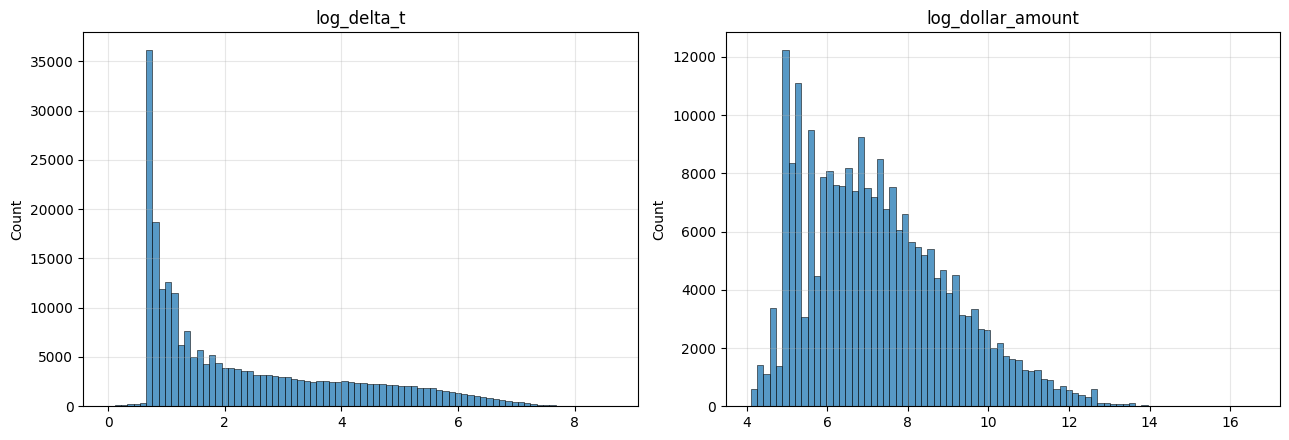

In [5]:
# plot raw distributions.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for idx, col in enumerate(FEATURE_COLUMNS):
    sns.histplot(data[col].values, ax=axes[idx], bins=80)
    axes[idx].set_title(col)
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## <b>Correct train/test split + train-fitted Copula + Min-Max transformation.</b>

Сначала делаем хронологическое разделение на train/test по сырым событиям. Затем fit-им `CopulaSpaceTransform` и `MinMaxScaler` только на train. Test переводится в model-space через empirical CDF и min-max параметры, построенные по train.


In [6]:
# ============================================================
# Correct time split BEFORE fitting any transformations.
# ============================================================

n_train_events = int(len(data) * TRAIN_FRACTION)

# Make sure both parts can produce at least one full SEQ_LEN window.
if n_train_events < SEQ_LEN:
    raise ValueError(
        f"Too few train events: {n_train_events}. Need at least SEQ_LEN={SEQ_LEN}."
    )
if len(data) - n_train_events < SEQ_LEN:
    raise ValueError(
        f"Too few test events: {len(data) - n_train_events}. Need at least SEQ_LEN={SEQ_LEN}."
    )

train_raw = data.iloc[:n_train_events].copy().reset_index(drop=True)
test_raw = data.iloc[n_train_events:].copy().reset_index(drop=True)

print("data rows:     ", len(data))
print("train_raw rows:", len(train_raw))
print("test_raw rows: ", len(test_raw))
print("train time range:", train_raw["timestamp"].min(), "->", train_raw["timestamp"].max())
print("test time range: ", test_raw["timestamp"].min(), "->", test_raw["timestamp"].max())


# ============================================================
# Train-fitted empirical copula transform for new/test values.
# Existing utilities.CopulaSpaceTransform.transform() transforms only the
# series used at construction time, so for test/new data we use the same
# empirical CDF fitted on train values explicitly.
# ============================================================

def empirical_copula_transform_from_train(
    new_values: np.ndarray,
    train_values: np.ndarray,
    eps: float = 1e-10
) -> np.ndarray:
    """
    Real space -> train-fitted empirical CDF -> normal copula space.

    This function does not look at test distribution. It uses only sorted train values.
    """
    new_values = np.asarray(new_values, dtype=np.float64).reshape(-1)
    train_sorted = np.sort(np.asarray(train_values, dtype=np.float64).reshape(-1))

    if train_sorted.size == 0:
        raise ValueError("train_values must be non-empty.")

    # Number of train observations <= each new value.
    ranks = np.searchsorted(train_sorted, new_values, side="right")

    # Smoothed empirical CDF, kept strictly inside (0, 1).
    u = (ranks + 0.5) / (train_sorted.size + 1.0)
    u = np.clip(u, eps, 1.0 - eps)

    return norm.ppf(u)


def minmax_transform_from_train(
    copula_values: np.ndarray,
    mm_transform,
    clip: bool = True
) -> np.ndarray:
    """
    Copula space -> train-fitted min-max model space.

    clip=True keeps model inputs in the [0, 1] range used during training.
    Values outside train support are mapped to the nearest train boundary.
    """
    denom = mm_transform._max - mm_transform._min
    if denom == 0:
        raise ValueError("MinMaxScaler has zero range.")

    out = (copula_values - mm_transform._min) / denom

    if clip:
        out = np.clip(out, 0.0, 1.0)

    return out


# ============================================================
# Fit transforms on train only; transform train and test separately.
# ============================================================

cs_transforms = {}
mm_transforms = {}
train_real_values = {}

train_cs_values = {}
test_cs_values = {}

train_mm_cs_values = {}
test_mm_cs_values = {}

for col in FEATURE_COLUMNS:
    train_values_col = train_raw[col].values.astype(np.float64)
    test_values_col = test_raw[col].values.astype(np.float64)

    # Fit empirical copula on train only.
    cs_transform = ut.CopulaSpaceTransform(time_series=train_values_col)
    train_cs_col = cs_transform.transform()

    # Fit min-max on train copula scores only.
    mm_transform = ut.MinMaxScaler(time_series=train_cs_col)
    train_mm_cs_col = mm_transform.transform()

    # Transform test using train-fitted empirical CDF and train-fitted min-max.
    test_cs_col = empirical_copula_transform_from_train(
        new_values=test_values_col,
        train_values=train_values_col
    )

    test_mm_cs_raw = minmax_transform_from_train(
        copula_values=test_cs_col,
        mm_transform=mm_transform,
        clip=False
    )
    outside_test_fraction = np.mean((test_mm_cs_raw < 0.0) | (test_mm_cs_raw > 1.0))

    test_mm_cs_col = minmax_transform_from_train(
        copula_values=test_cs_col,
        mm_transform=mm_transform,
        clip=True
    )

    cs_transforms[col] = cs_transform
    mm_transforms[col] = mm_transform
    train_real_values[col] = train_values_col

    train_cs_values[col] = train_cs_col
    test_cs_values[col] = test_cs_col

    train_mm_cs_values[col] = train_mm_cs_col
    test_mm_cs_values[col] = test_mm_cs_col

    print("=" * 80)
    print(col)
    print("train real mean/std:", train_values_col.mean(), train_values_col.std())
    print("test  real mean/std:", test_values_col.mean(), test_values_col.std())
    print("train model-space min/max:", train_mm_cs_col.min(), train_mm_cs_col.max())
    print("test raw model-space min/max before clipping:", test_mm_cs_raw.min(), test_mm_cs_raw.max())
    print("test outside [0, 1] fraction before clipping:", outside_test_fraction)


train_features_copula = np.column_stack([
    train_mm_cs_values[col] for col in FEATURE_COLUMNS
]).astype(np.float32)

test_features_copula = np.column_stack([
    test_mm_cs_values[col] for col in FEATURE_COLUMNS
]).astype(np.float32)

print("=" * 80)
print("train_features_copula shape:", train_features_copula.shape)
print("test_features_copula shape: ", test_features_copula.shape)
print("train min/max:", train_features_copula.min(), train_features_copula.max())
print("test  min/max:", test_features_copula.min(), test_features_copula.max())


data rows:      236066
train_raw rows: 188852
test_raw rows:  47214
train time range: 2025-11-01 00:03:11.322000+00:00 -> 2026-03-15 23:58:54.369000+00:00
test time range:  2026-03-15 23:59:23.160000+00:00 -> 2026-04-28 23:32:26.199000+00:00
log_delta_t
train real mean/std: 2.3065484140245416 1.7092212063555008
test  real mean/std: 2.543260406527955 1.8274717449475504
train model-space min/max: 0.0 1.0
test raw model-space min/max before clipping: -1.2229840971244894e-07 0.9271188155281462
test outside [0, 1] fraction before clipping: 0.02088363620959885
log_dollar_amount
train real mean/std: 7.240546423890885 1.7507339902768635
test  real mean/std: 7.423874078404407 1.9513457880146627
train model-space min/max: 0.0 1.0
test raw model-space min/max before clipping: 0.13216638528762528 0.9614625114045012
test outside [0, 1] fraction before clipping: 0.0
train_features_copula shape: (188852, 2)
test_features_copula shape:  (47214, 2)
train min/max: 0.0 1.0
test  min/max: 0.0 0.9614625


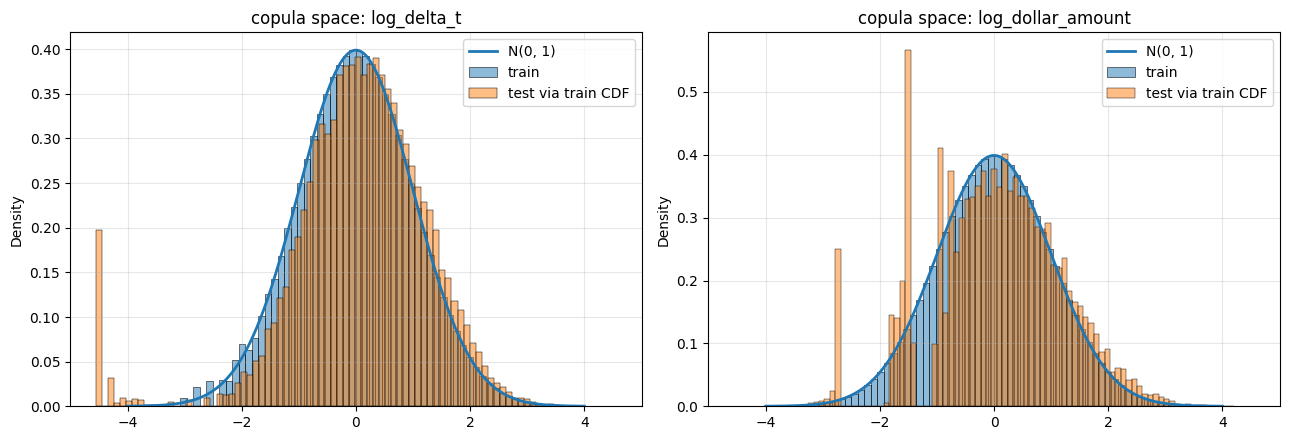

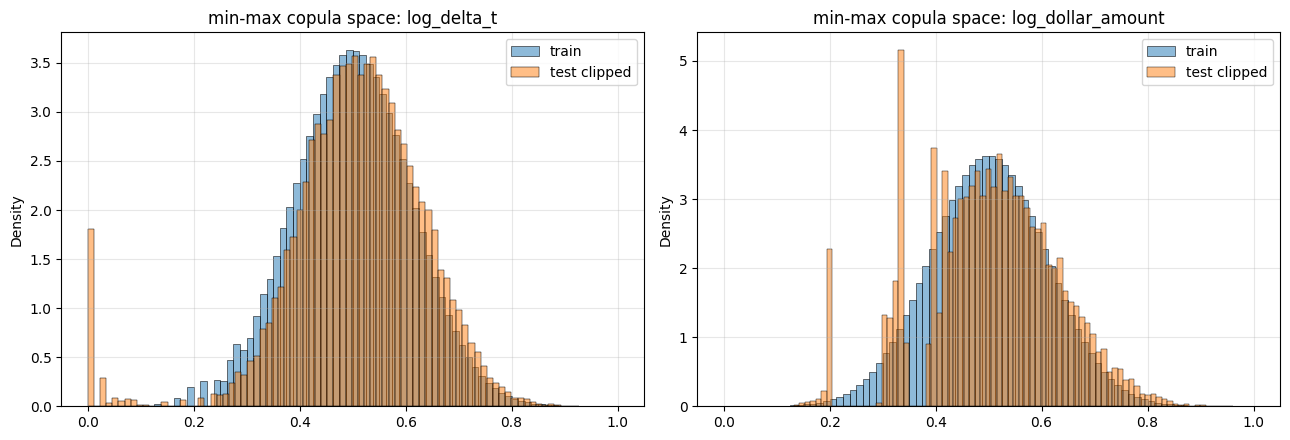

In [7]:
# Plot train-fitted copula-space and min-max distributions.
grid = np.linspace(-4, 4, 500)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for idx, col in enumerate(FEATURE_COLUMNS):
    sns.histplot(train_cs_values[col].reshape(-1), ax=axes[idx], bins=80, stat="density", label="train", alpha=0.5)
    sns.histplot(test_cs_values[col].reshape(-1), ax=axes[idx], bins=80, stat="density", label="test via train CDF", alpha=0.5)
    axes[idx].plot(grid, norm.pdf(grid, loc=0, scale=1), linewidth=2, label="N(0, 1)")
    axes[idx].set_title(f"copula space: {col}")
    axes[idx].grid(alpha=0.3)
    axes[idx].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for idx, col in enumerate(FEATURE_COLUMNS):
    sns.histplot(train_mm_cs_values[col].reshape(-1), ax=axes[idx], bins=80, stat="density", label="train", alpha=0.5)
    sns.histplot(test_mm_cs_values[col].reshape(-1), ax=axes[idx], bins=80, stat="density", label="test clipped", alpha=0.5)
    axes[idx].set_title(f"min-max copula space: {col}")
    axes[idx].grid(alpha=0.3)
    axes[idx].legend()
plt.tight_layout()
plt.show()


## <b>Training and conditional datasets.</b>

In [8]:
class NumpyWindowDataset(Dataset):
    """Minimal dataset compatible with Diffusion-TS Trainer."""
    def __init__(self, data: np.ndarray):
        assert data.ndim == 3
        self.data = torch.tensor(data, dtype=torch.float32)
        self.window = int(data.shape[1])
        self.var_num = int(data.shape[2])
        self.auto_norm = False

    def __len__(self):
        return self.data.shape[0]

    def __getitem__(self, idx):
        return self.data[idx]


class ConditionalWindowDataset(Dataset):
    """
    Dataset for mask-based conditional generation.

    mask == True  : known values, fixed during sampling.
    mask == False : unknown values, sampled by diffusion model.
    """
    def __init__(self, data: np.ndarray, mask: np.ndarray):
        assert data.shape == mask.shape
        assert data.ndim == 3

        self.data = torch.tensor(data, dtype=torch.float32)
        self.mask = torch.tensor(mask, dtype=torch.bool)
        self.window = int(data.shape[1])
        self.var_num = int(data.shape[2])
        self.auto_norm = False

    def __len__(self):
        return self.data.shape[0]

    def __getitem__(self, idx):
        return self.data[idx], self.mask[idx]


def make_windows(x: np.ndarray, seq_len: int, stride: int) -> np.ndarray:
    """Build time-ordered windows with a chosen stride."""
    if x.ndim != 2:
        raise ValueError("x must have shape (n_events, n_channels).")
    if len(x) < seq_len:
        raise ValueError("Not enough events for one full window.")

    starts = np.arange(0, len(x) - seq_len + 1, stride)
    windows = np.stack([x[start:start + seq_len] for start in starts], axis=0)
    return windows.astype(np.float32)


def make_forecast_mask(windows: np.ndarray, hist_len: int) -> np.ndarray:
    """
    True for past values, False for future values.
    Shape is the same as windows: (n_windows, seq_len, channels).
    """
    mask = np.zeros_like(windows, dtype=bool)
    mask[:, :hist_len, :] = True
    return mask

In [9]:
# Build windows separately inside train and test.
# This prevents any window from crossing the train/test boundary.
train_windows = make_windows(
    x=train_features_copula,
    seq_len=SEQ_LEN,
    stride=TRAIN_WINDOW_STRIDE
)

test_windows = make_windows(
    x=test_features_copula,
    seq_len=SEQ_LEN,
    stride=TEST_WINDOW_STRIDE
)

print("train_windows shape:", train_windows.shape)
print("test_windows shape: ", test_windows.shape)
print("train events used:", len(train_features_copula))
print("test events used: ", len(test_features_copula))
print("TRAIN_WINDOW_STRIDE:", TRAIN_WINDOW_STRIDE)
print("TEST_WINDOW_STRIDE: ", TEST_WINDOW_STRIDE)

# Sanity check: these windows are built from disjoint raw time intervals.
print("train last timestamp:", train_raw["timestamp"].iloc[-1])
print("test first timestamp:", test_raw["timestamp"].iloc[0])


train_windows shape: (2947, 256, 2)
test_windows shape:  (734, 256, 2)
train events used: 188852
test events used:  47214
TRAIN_WINDOW_STRIDE: 64
TEST_WINDOW_STRIDE:  64
train last timestamp: 2026-03-15 23:58:54.369000+00:00
test first timestamp: 2026-03-15 23:59:23.160000+00:00


In [10]:
# create training dataloader.
dataset = NumpyWindowDataset(train_windows)

train_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    num_workers=0
)

dl_info = {
    "dataset": dataset,
    "dataloader": train_loader,
    "train_dataloader": train_loader,
    "train_loader": train_loader,
    "test_dataloader": train_loader,
    "test_loader": train_loader,
}

print("dataset length:", len(dataset))
print("window:", dataset.window)
print("var_num:", dataset.var_num)
print("batches:", len(train_loader))

dataset length: 2947
window: 256
var_num: 2
batches: 47


## <b>Create 2-channel config and model.</b>

In [11]:
def recursive_patch_model_shape(obj, seq_len: int, feature_size: int):
    """
    Recursively patches common shape keys in a Diffusion-TS yaml config.
    Main required keys for Diffusion_TS are seq_length and feature_size.
    """
    if isinstance(obj, dict):
        for key, value in obj.items():
            if key in {"seq_length", "seq_len"}:
                obj[key] = seq_len
            elif key in {"feature_size", "n_feat", "input_size", "enc_in", "c_in", "channels", "var_num"}:
                obj[key] = feature_size
            else:
                recursive_patch_model_shape(value, seq_len, feature_size)
    elif isinstance(obj, list):
        for value in obj:
            recursive_patch_model_shape(value, seq_len, feature_size)


def prepare_2ch_config(config_path: Path, source_config_path: Path) -> Path:
    """
    Creates a local 2-channel config if it does not exist.
    If CONFIG_PATH already exists, it is overwritten to avoid stale 4ch parameters.
    """
    if not source_config_path.exists() and not config_path.exists():
        raise FileNotFoundError(
            f"Neither SOURCE_CONFIG_PATH nor CONFIG_PATH exists.\n"
            f"SOURCE_CONFIG_PATH={source_config_path}\n"
            f"CONFIG_PATH={config_path}"
        )

    base_path = source_config_path if source_config_path.exists() else config_path

    with open(base_path, "r", encoding="utf-8") as f:
        cfg = yaml.safe_load(f)

    cfg = copy.deepcopy(cfg)

    # Patch model shape.
    recursive_patch_model_shape(cfg.get("model", cfg), SEQ_LEN, INPUT_CHANNELS)

    # Patch output folder used by Trainer.
    if "solver" not in cfg:
        raise KeyError("Config must contain a 'solver' section.")

    cfg["solver"]["results_folder"] = str(RESULTS_DIR)

    with open(config_path, "w", encoding="utf-8") as f:
        yaml.safe_dump(cfg, f, sort_keys=False, allow_unicode=True)

    return config_path


CONFIG_PATH = prepare_2ch_config(CONFIG_PATH, SOURCE_CONFIG_PATH)
configs = load_yaml_config(str(CONFIG_PATH))

print("Prepared config:", CONFIG_PATH)
print("model params:")
print(configs.get("model", {}).get("params", {}))
print("solver results_folder:", configs["solver"].get("results_folder"))

Prepared config: c:\Users\tnovi\Desktop\Diffusion_TS\Diffusion-TS\exp_liquidations_2ch_dt_dollar_amount_forecast_clean_split\liquidations_2ch_dt_dollar_amount_forecast_clean_split_config.yaml
model params:
{'seq_length': 256, 'feature_size': 2, 'n_layer_enc': 1, 'n_layer_dec': 2, 'd_model': 64, 'timesteps': 500, 'sampling_timesteps': 500, 'loss_type': 'l1', 'beta_schedule': 'cosine', 'n_heads': 4, 'mlp_hidden_times': 4, 'attn_pd': 0.0, 'resid_pd': 0.0, 'kernel_size': 1, 'padding_size': 0}
solver results_folder: c:\Users\tnovi\Desktop\Diffusion_TS\Diffusion-TS\exp_liquidations_2ch_dt_dollar_amount_forecast_clean_split\results


In [12]:
class ArgsLiquidations2ChForecast:
    def __init__(self):
        self.name = "liquidations_2ch_dt_dollar_amount_forecast"
        self.config_path = str(CONFIG_PATH)
        self.save_dir = str(RESULTS_DIR)
        self.gpu = 0
        os.makedirs(self.save_dir, exist_ok=True)


args = ArgsLiquidations2ChForecast()

device = torch.device(f"cuda:{args.gpu}" if torch.cuda.is_available() else "cpu")
model = instantiate_from_config(configs["model"]).to(device)

trainer = Trainer(
    config=configs,
    args=args,
    model=model,
    dataloader=dl_info
)

if LOAD_MILESTONE is not None:
    trainer.load(LOAD_MILESTONE, verbose=True)

n_params = sum(p.numel() for p in model.parameters())

print(f"Model params: {n_params / 1e6:.2f}M")
print("Device:", device)
print("model.seq_length:", model.seq_length)
print("model.feature_size:", model.feature_size)

Model params: 0.53M
Device: cuda:0
model.seq_length: 256
model.feature_size: 2


## <b>Train.</b>

In [13]:
if RUN_TRAIN:
    trainer.train()
    print("Training complete.")
else:
    print("Training skipped. Make sure LOAD_MILESTONE is set or model weights are already loaded.")

  0%|          | 0/12000 [00:00<?, ?it/s]

training complete
Training complete.


## <b>Conditional forecasting: first 192 events are known, next 64 are sampled.</b>

In [14]:
def to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)


# Use held-out windows for conditional forecasting.
n_forecast = min(N_FORECAST_PATHS, len(test_windows))
forecast_windows = test_windows[:n_forecast].copy()
forecast_mask = make_forecast_mask(forecast_windows, hist_len=HIST_LEN)

forecast_dataset = ConditionalWindowDataset(
    data=forecast_windows,
    mask=forecast_mask
)

forecast_loader = DataLoader(
    forecast_dataset,
    batch_size=SAMPLE_BATCH,
    shuffle=False,
    drop_last=False,
    num_workers=0
)

print("forecast_windows shape:", forecast_windows.shape)
print("forecast_mask shape:   ", forecast_mask.shape)
print("known part: ", forecast_mask[:, :HIST_LEN, :].all())
print("future part:", forecast_mask[:, HIST_LEN:, :].any())

forecast_windows shape: (500, 256, 2)
forecast_mask shape:    (500, 256, 2)
known part:  True
future part: False


In [15]:
forecast_synthetic, forecast_real, forecast_masks = trainer.restore(
    raw_dataloader=forecast_loader,
    shape=[SEQ_LEN, INPUT_CHANNELS],
    coef=FORECAST_COEF,
    stepsize=FORECAST_STEPSIZE,
    sampling_steps=FORECAST_SAMPLING_STEPS
)

forecast_synthetic = to_numpy(forecast_synthetic)[:n_forecast]
forecast_real = to_numpy(forecast_real)[:n_forecast]
forecast_masks = to_numpy(forecast_masks)[:n_forecast].astype(bool)

print("forecast_synthetic shape:", forecast_synthetic.shape)
print("forecast_real shape:     ", forecast_real.shape)
print("forecast_masks shape:    ", forecast_masks.shape)

known_error = np.max(np.abs(forecast_synthetic[forecast_masks] - forecast_real[forecast_masks]))
print("max known-part error:", known_error)

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

forecast_synthetic shape: (500, 256, 2)
forecast_real shape:      (500, 256, 2)
forecast_masks shape:     (500, 256, 2)
max known-part error: 0.0


## <b>Inverse transformation.</b>

In [16]:
def inverse_windows_from_model_space(windows_mm_cs: np.ndarray) -> dict[str, np.ndarray]:
    """
    Inverse transform windows from model space to real feature space.

    Input shape:  (n_windows, seq_len, n_channels)
    Output: dict column_name -> array with shape (n_windows, seq_len)
    """
    if windows_mm_cs.ndim != 3:
        raise ValueError("windows_mm_cs must have shape (n_windows, seq_len, n_channels).")
    if windows_mm_cs.shape[2] != len(FEATURE_COLUMNS):
        raise ValueError("Unexpected number of channels.")

    result = {}

    for channel_id, col in enumerate(FEATURE_COLUMNS):
        mm_cs_flat = windows_mm_cs[:, :, channel_id].reshape(-1)
        cs_flat = mm_transforms[col].inverse_transform(min_max_series=mm_cs_flat)
        real_flat = cs_transforms[col].invert_transform(copula_series=cs_flat)
        result[col] = real_flat.reshape(windows_mm_cs.shape[0], windows_mm_cs.shape[1])

    return result


real_forecast_features = inverse_windows_from_model_space(forecast_real)
syn_forecast_features = inverse_windows_from_model_space(forecast_synthetic)

# Future-only arrays.
real_future = {
    col: arr[:, HIST_LEN:] for col, arr in real_forecast_features.items()
}
syn_future = {
    col: arr[:, HIST_LEN:] for col, arr in syn_forecast_features.items()
}

print("real future shape:", {col: value.shape for col, value in real_future.items()})
print("syn future shape: ", {col: value.shape for col, value in syn_future.items()})

real future shape: {'log_delta_t': (500, 64), 'log_dollar_amount': (500, 64)}
syn future shape:  {'log_delta_t': (500, 64), 'log_dollar_amount': (500, 64)}


## <b>Visual check of individual paths.</b>

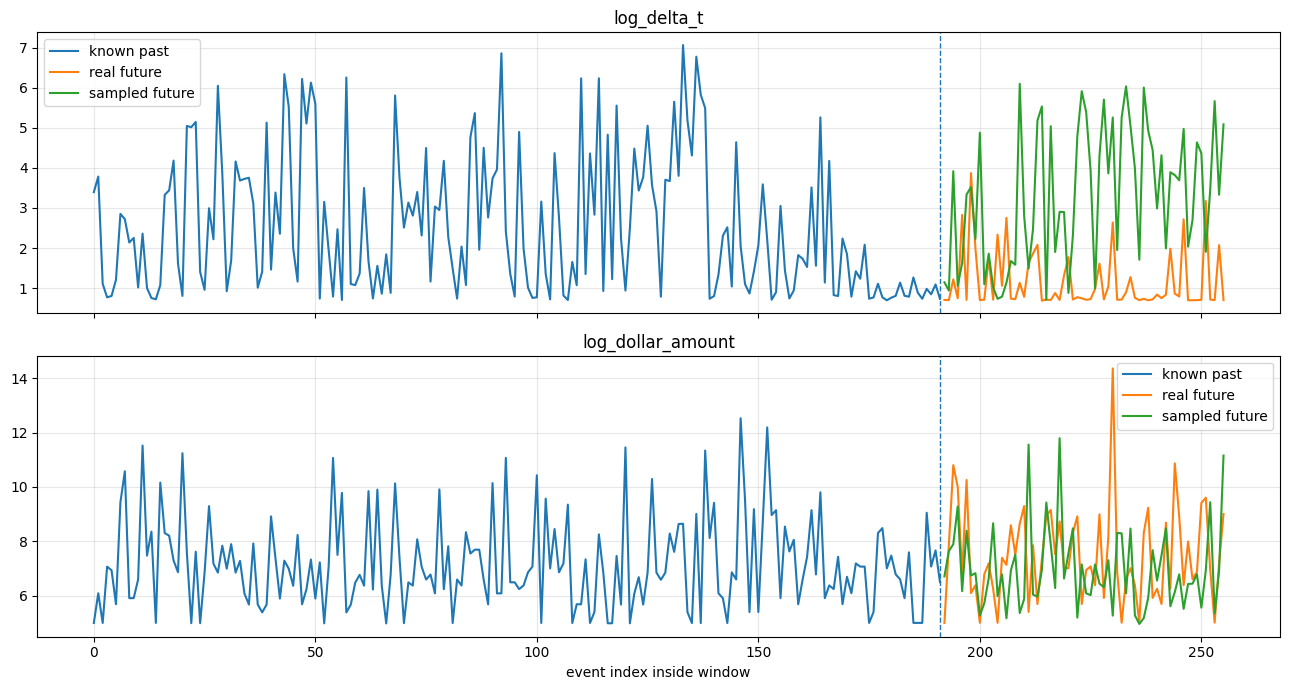

In [17]:
def plot_forecast_example(path_id: int = 0):
    if path_id < 0 or path_id >= n_forecast:
        raise ValueError(f"path_id must be in [0, {n_forecast - 1}].")

    time_index = np.arange(SEQ_LEN)
    future_index = np.arange(HIST_LEN, SEQ_LEN)

    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

    for ax_id, col in enumerate(FEATURE_COLUMNS):
        ax = axes[ax_id]

        real_path = real_forecast_features[col][path_id]
        syn_path = syn_forecast_features[col][path_id]

        ax.plot(time_index[:HIST_LEN], real_path[:HIST_LEN], label="known past")
        ax.plot(future_index, real_path[HIST_LEN:], label="real future")
        ax.plot(future_index, syn_path[HIST_LEN:], label="sampled future")
        ax.axvline(HIST_LEN - 1, linestyle="--", linewidth=1)
        ax.set_title(col)
        ax.grid(alpha=0.3)
        ax.legend()

    axes[-1].set_xlabel("event index inside window")
    plt.tight_layout()
    plt.show()


plot_forecast_example(path_id=0)

## <b>Future-only distribution diagnostics.</b>

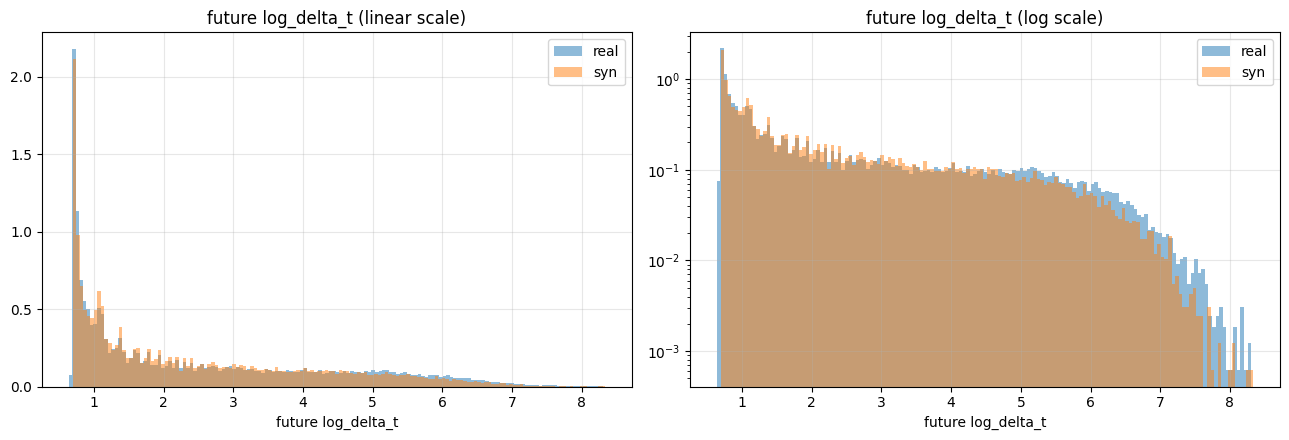

future log_delta_t
real mean/std: 2.5023364351078667 1.817208544244081
syn  mean/std: 2.3955729621532567 1.6813774398666526
real p1/p50/p99: [0.69513991 1.80721718 6.93885931]
syn  p1/p50/p99: [0.69664107 1.79292544 6.68988103]
KS=0.03581, W1=0.128935


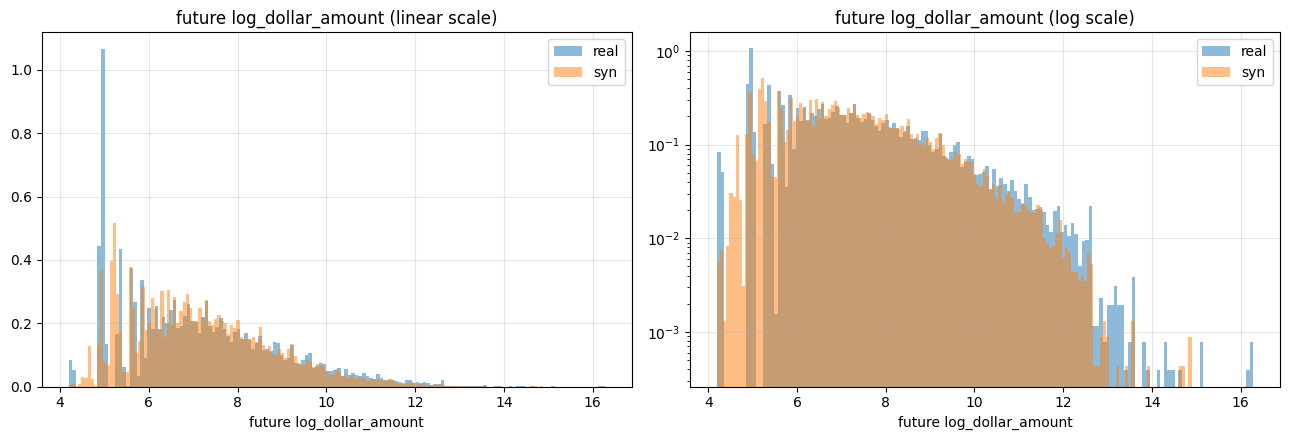

future log_dollar_amount
real mean/std: 7.178600674778994 1.7652336922577454
syn  mean/std: 7.150738371794845 1.596533140900726
real p1/p50/p99: [ 4.3153401   6.93452091 12.00064367]
syn  p1/p50/p99: [ 4.64564976  6.94103734 11.47999205]
KS=0.08641, W1=0.137927


In [18]:
# Compare only generated future part: events 193..256.
for col in FEATURE_COLUMNS:
    us.plot_real_vs_synthetic_distribution(
        name=f"future {col}",
        real_series=real_future[col].reshape(-1),
        syn_series=syn_future[col].reshape(-1)
    )

    us.pooled_metrics(
        name=f"future {col}",
        real_series=real_future[col].reshape(-1),
        syn_series=syn_future[col].reshape(-1)
    )

In [19]:
# Pointwise error is not the main metric for stochastic sampling,
# but it is useful as a rough diagnostic against the held-out continuation.
for col in FEATURE_COLUMNS:
    err = syn_future[col] - real_future[col]
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err ** 2))

    print("=" * 80)
    print(col)
    print("future MAE: ", mae)
    print("future RMSE:", rmse)

log_delta_t
future MAE:  1.8894877684922844
future RMSE: 2.455273751951143
log_dollar_amount
future MAE:  1.8799863557825658
future RMSE: 2.3689180522923134


## <b>Future-only joint distribution.</b>

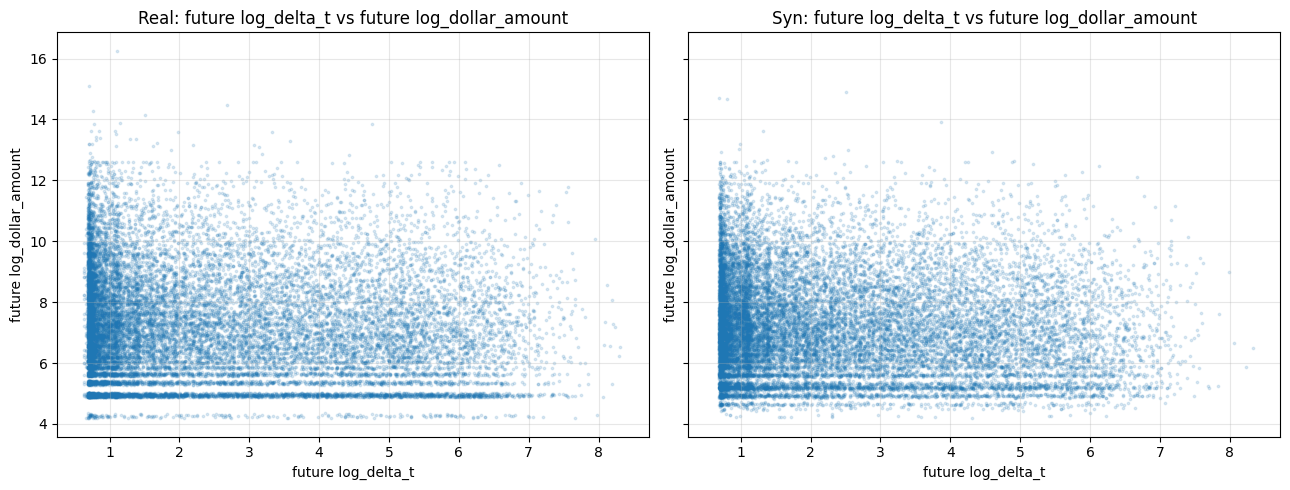

future log_delta_t vs future log_dollar_amount
Real Pearson:  -0.07829178868153662
Syn  Pearson:  -0.07443259417773296
Real Spearman: -0.07777961077122375
Syn  Spearman: -0.07444636343807978


In [20]:
us.plot_x_vs_y_distribution(
    x_name="future log_delta_t",
    y_name="future log_dollar_amount",
    real_x=real_future["log_delta_t"].reshape(-1),
    real_y=real_future["log_dollar_amount"].reshape(-1),
    syn_x=syn_future["log_delta_t"].reshape(-1),
    syn_y=syn_future["log_dollar_amount"].reshape(-1)
)

print("=" * 80)
print("future log_delta_t vs future log_dollar_amount")
print(
    "Real Pearson: ",
    us.pooled_pearson(
        real_future["log_delta_t"].reshape(-1),
        real_future["log_dollar_amount"].reshape(-1)
    )
)
print(
    "Syn  Pearson: ",
    us.pooled_pearson(
        syn_future["log_delta_t"].reshape(-1),
        syn_future["log_dollar_amount"].reshape(-1)
    )
)
print(
    "Real Spearman:",
    us.pooled_spearman(
        real_future["log_delta_t"].reshape(-1),
        real_future["log_dollar_amount"].reshape(-1)
    )
)
print(
    "Syn  Spearman:",
    us.pooled_spearman(
        syn_future["log_delta_t"].reshape(-1),
        syn_future["log_dollar_amount"].reshape(-1)
    )
)

## <b>Future-only lag diagnostics.</b>

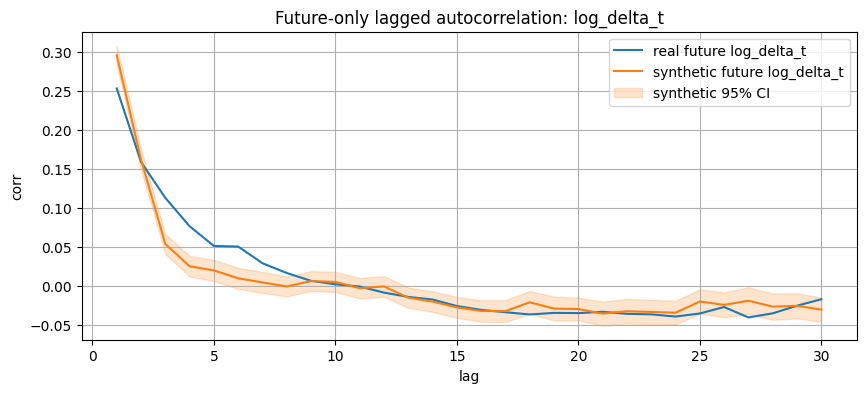

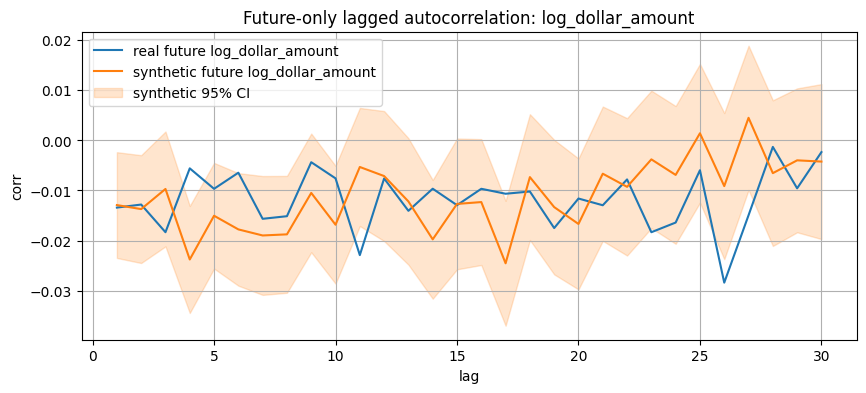

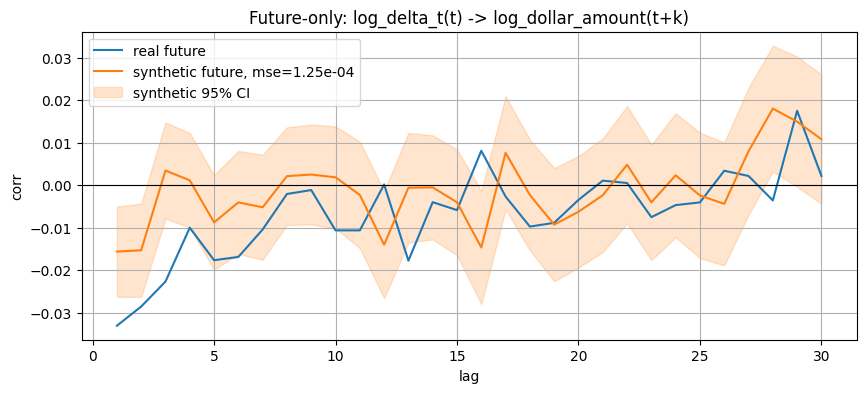

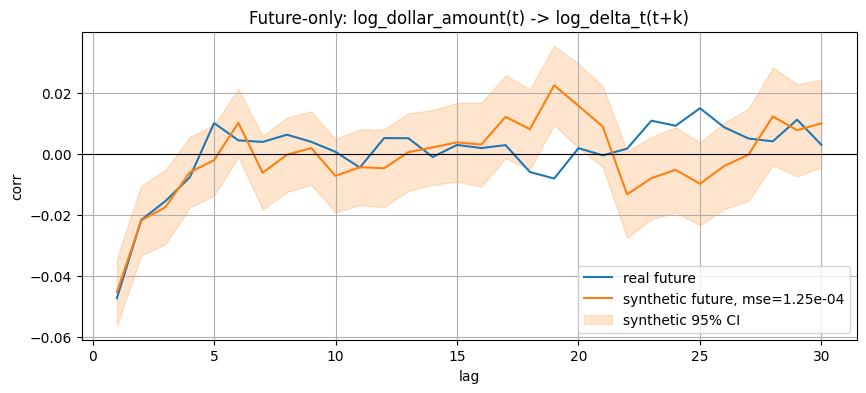

In [21]:
MAX_LAG = min(30, PRED_LEN - 1)

real_future_log_delta_t_matrix = real_future["log_delta_t"]
real_future_log_dollar_amount_matrix = real_future["log_dollar_amount"]

syn_future_log_delta_t_matrix = syn_future["log_delta_t"]
syn_future_log_dollar_amount_matrix = syn_future["log_dollar_amount"]

real_dt_acf, syn_dt_acf = us.plot_real_vs_synthetic_lagged_correlation(
    real_matrix=real_future_log_delta_t_matrix,
    synthetic_matrix=syn_future_log_delta_t_matrix,
    max_lag=MAX_LAG,
    title="Future-only lagged autocorrelation: log_delta_t",
    real_label="real future log_delta_t",
    synthetic_label="synthetic future log_delta_t",
)

real_amount_acf, syn_amount_acf = us.plot_real_vs_synthetic_lagged_correlation(
    real_matrix=real_future_log_dollar_amount_matrix,
    synthetic_matrix=syn_future_log_dollar_amount_matrix,
    max_lag=MAX_LAG,
    title="Future-only lagged autocorrelation: log_dollar_amount",
    real_label="real future log_dollar_amount",
    synthetic_label="synthetic future log_dollar_amount",
)

real_dt_to_amount, syn_dt_to_amount = us.plot_real_vs_synthetic_cross_lagged_correlation(
    real_x_matrix=real_future_log_delta_t_matrix,
    real_y_matrix=real_future_log_dollar_amount_matrix,
    synthetic_x_matrix=syn_future_log_delta_t_matrix,
    synthetic_y_matrix=syn_future_log_dollar_amount_matrix,
    max_lag=MAX_LAG,
    title="Future-only: log_delta_t(t) -> log_dollar_amount(t+k)",
    real_label="real future",
    synthetic_label="synthetic future"
)

real_amount_to_dt, syn_amount_to_dt = us.plot_real_vs_synthetic_cross_lagged_correlation(
    real_x_matrix=real_future_log_dollar_amount_matrix,
    real_y_matrix=real_future_log_delta_t_matrix,
    synthetic_x_matrix=syn_future_log_dollar_amount_matrix,
    synthetic_y_matrix=syn_future_log_delta_t_matrix,
    max_lag=MAX_LAG,
    title="Future-only: log_dollar_amount(t) -> log_delta_t(t+k)",
    real_label="real future",
    synthetic_label="synthetic future"
)

## <b>Save forecast artifacts.</b>

In [22]:
# Save arrays for later analysis.
np.save(RESULTS_DIR / "forecast_synthetic_mm_cs.npy", forecast_synthetic)
np.save(RESULTS_DIR / "forecast_real_mm_cs.npy", forecast_real)
np.save(RESULTS_DIR / "forecast_masks.npy", forecast_masks)

np.savez(
    RESULTS_DIR / "forecast_future_real_space.npz",
    real_future_log_delta_t=real_future["log_delta_t"],
    real_future_log_dollar_amount=real_future["log_dollar_amount"],
    syn_future_log_delta_t=syn_future["log_delta_t"],
    syn_future_log_dollar_amount=syn_future["log_dollar_amount"],
)

print("Saved to:", RESULTS_DIR)

Saved to: c:\Users\tnovi\Desktop\Diffusion_TS\Diffusion-TS\exp_liquidations_2ch_dt_dollar_amount_forecast_clean_split\results


## <b>How to forecast from a new 192-event path.</b>

In [23]:
def transform_new_192_events(raw_192_df: pd.DataFrame) -> np.ndarray:
    """
    raw_192_df must contain columns:
        log_delta_t, log_dollar_amount

    Returns model-space array with shape (1, 256, 2).
    First 192 events are filled by transformed history, future part is zero placeholder.

    Important: all transformations use train-fitted empirical CDF and train-fitted min-max.
    """
    if len(raw_192_df) != HIST_LEN:
        raise ValueError(f"raw_192_df must contain exactly {HIST_LEN} rows.")

    x = np.zeros((1, SEQ_LEN, INPUT_CHANNELS), dtype=np.float32)

    for ch, col in enumerate(FEATURE_COLUMNS):
        cs_new = empirical_copula_transform_from_train(
            new_values=raw_192_df[col].values,
            train_values=train_real_values[col]
        )
        mm_cs_new = minmax_transform_from_train(
            copula_values=cs_new,
            mm_transform=mm_transforms[col],
            clip=True
        )
        x[0, :HIST_LEN, ch] = mm_cs_new.astype(np.float32)

    return x


def sample_next_64_from_raw_192(raw_192_df: pd.DataFrame, batch_size: int = 1):
    """
    Samples next 64 events from a new 192-event liquidation path.
    Returns real-space dict with keys log_delta_t and log_dollar_amount.
    """
    x_cond = transform_new_192_events(raw_192_df)
    mask = make_forecast_mask(x_cond, hist_len=HIST_LEN)

    ds = ConditionalWindowDataset(x_cond, mask)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False, drop_last=False, num_workers=0)

    syn, real, m = trainer.restore(
        raw_dataloader=dl,
        shape=[SEQ_LEN, INPUT_CHANNELS],
        coef=FORECAST_COEF,
        stepsize=FORECAST_STEPSIZE,
        sampling_steps=FORECAST_SAMPLING_STEPS
    )

    syn = to_numpy(syn)[:1]
    syn_real_space = inverse_windows_from_model_space(syn)

    return {
        col: syn_real_space[col][0, HIST_LEN:] for col in FEATURE_COLUMNS
    }


# Example usage:
# raw_192_df = test_raw[FEATURE_COLUMNS].iloc[:HIST_LEN].copy()
# sampled_future = sample_next_64_from_raw_192(raw_192_df)
# sampled_future["log_delta_t"].shape, sampled_future["log_dollar_amount"].shape


In [24]:
real_forecast_features = inverse_windows_from_model_space(forecast_real)
syn_forecast_features = inverse_windows_from_model_space(forecast_synthetic)

In [25]:
def window_stats(x: np.ndarray) -> dict:
    """
    x shape: (n_windows, length, channels)

    channel 0 = log_delta_t
    channel 1 = log_dollar_amount
    """
    return {
        "mean_log_delta_t": x[:, :, 0].mean(axis=1),
        "p95_log_delta_t": np.quantile(x[:, :, 0], 0.95, axis=1),

        "mean_log_dollar_amount": x[:, :, 1].mean(axis=1),
        "p95_log_dollar_amount": np.quantile(x[:, :, 1], 0.95, axis=1),
        "max_log_dollar_amount": x[:, :, 1].max(axis=1),
    }


# Собираем обратно dict -> ndarray.
# Получаем массивы формы:
# (n_forecast, SEQ_LEN, 2)
real_forecast_real_space = np.stack(
    [
        real_forecast_features["log_delta_t"],
        real_forecast_features["log_dollar_amount"],
    ],
    axis=-1
)

syn_forecast_real_space = np.stack(
    [
        syn_forecast_features["log_delta_t"],
        syn_forecast_features["log_dollar_amount"],
    ],
    axis=-1
)

print("real_forecast_real_space shape:", real_forecast_real_space.shape)
print("syn_forecast_real_space shape: ", syn_forecast_real_space.shape)


# Разделяем на известное прошлое и будущее.
real_past_arr = real_forecast_real_space[:, :HIST_LEN, :]
real_future_arr = real_forecast_real_space[:, HIST_LEN:, :]

syn_past_arr = syn_forecast_real_space[:, :HIST_LEN, :]
syn_future_arr = syn_forecast_real_space[:, HIST_LEN:, :]

print("real_past_arr shape:  ", real_past_arr.shape)
print("real_future_arr shape:", real_future_arr.shape)
print("syn_past_arr shape:   ", syn_past_arr.shape)
print("syn_future_arr shape: ", syn_future_arr.shape)


# Считаем статистики.
real_past_stats = window_stats(real_past_arr)
real_future_stats = window_stats(real_future_arr)

syn_past_stats = window_stats(syn_past_arr)
syn_future_stats = window_stats(syn_future_arr)

real_forecast_real_space shape: (500, 256, 2)
syn_forecast_real_space shape:  (500, 256, 2)
real_past_arr shape:   (500, 192, 2)
real_future_arr shape: (500, 64, 2)
syn_past_arr shape:    (500, 192, 2)
syn_future_arr shape:  (500, 64, 2)


In [26]:
from scipy.stats import spearmanr


def compare_past_future_relation(
    past_stats_real: dict,
    future_stats_real: dict,
    future_stats_syn: dict,
    past_key: str,
    future_key: str
):
    """
    Uses the same real past for real and synthetic future.
    The known past is fixed by the mask, so this is the correct conditional comparison.
    """
    real_corr = spearmanr(
        past_stats_real[past_key],
        future_stats_real[future_key]
    ).correlation

    syn_corr = spearmanr(
        past_stats_real[past_key],
        future_stats_syn[future_key]
    ).correlation

    print("=" * 80)
    print(f"{past_key} -> {future_key}")
    print(f"real Spearman: {real_corr:.4f}")
    print(f"syn  Spearman: {syn_corr:.4f}")
    print(f"abs diff:      {abs(real_corr - syn_corr):.4f}")


for past_key in real_past_stats.keys():
    for future_key in real_future_stats.keys():
        compare_past_future_relation(
            past_stats_real=real_past_stats,
            future_stats_real=real_future_stats,
            future_stats_syn=syn_future_stats,
            past_key=past_key,
            future_key=future_key
        )


mean_log_delta_t -> mean_log_delta_t
real Spearman: 0.2995
syn  Spearman: 0.4230
abs diff:      0.1234
mean_log_delta_t -> p95_log_delta_t
real Spearman: 0.3809
syn  Spearman: 0.4753
abs diff:      0.0944
mean_log_delta_t -> mean_log_dollar_amount
real Spearman: -0.2710
syn  Spearman: -0.3829
abs diff:      0.1119
mean_log_delta_t -> p95_log_dollar_amount
real Spearman: -0.1775
syn  Spearman: -0.1248
abs diff:      0.0527
mean_log_delta_t -> max_log_dollar_amount
real Spearman: -0.1161
syn  Spearman: -0.0628
abs diff:      0.0533
p95_log_delta_t -> mean_log_delta_t
real Spearman: 0.2674
syn  Spearman: 0.3639
abs diff:      0.0965
p95_log_delta_t -> p95_log_delta_t
real Spearman: 0.3777
syn  Spearman: 0.4038
abs diff:      0.0261
p95_log_delta_t -> mean_log_dollar_amount
real Spearman: -0.2296
syn  Spearman: -0.3050
abs diff:      0.0754
p95_log_delta_t -> p95_log_dollar_amount
real Spearman: -0.1524
syn  Spearman: -0.1032
abs diff:      0.0491
p95_log_delta_t -> max_log_dollar_amount
r

In [27]:
known_error_real_space = np.max(
    np.abs(
        syn_forecast_real_space[:, :HIST_LEN, :]
        -
        real_forecast_real_space[:, :HIST_LEN, :]
    )
)

print("known past max abs error:", known_error_real_space)

known past max abs error: 0.0


In [28]:
# ============================================================
# Multi-sample conditional forecasting:
# same past -> many sampled futures
# ============================================================

N_CONTEXTS_EVAL = min(N_CONTEXTS, len(test_windows))

base_windows = test_windows[:N_CONTEXTS_EVAL].copy()

print("base_windows shape:", base_windows.shape)
print("K_SAMPLES:", K_SAMPLES)
print("N_CONTEXTS_EVAL:", N_CONTEXTS_EVAL)
print("FORECAST_COEF:", FORECAST_COEF)
print("FORECAST_STEPSIZE:", FORECAST_STEPSIZE)
print("FORECAST_SAMPLING_STEPS:", FORECAST_SAMPLING_STEPS)


# Repeat every test window K times:
# window_0, window_0, ..., window_0,
# window_1, window_1, ..., window_1, ...
repeated_windows = np.repeat(
    base_windows,
    repeats=K_SAMPLES,
    axis=0
)

print("repeated_windows shape:", repeated_windows.shape)


# Mask:
# first HIST_LEN events are known,
# last PRED_LEN events are generated.
multi_mask = np.zeros_like(repeated_windows, dtype=bool)
multi_mask[:, :HIST_LEN, :] = True
multi_mask[:, HIST_LEN:, :] = False


multi_dataset = ConditionalWindowDataset(
    data=repeated_windows,
    mask=multi_mask
)

multi_loader = DataLoader(
    multi_dataset,
    batch_size=SAMPLE_BATCH,
    shuffle=False,
    drop_last=False,
    num_workers=0
)


multi_synthetic, multi_real, multi_masks = trainer.restore(
    raw_dataloader=multi_loader,
    shape=[SEQ_LEN, INPUT_CHANNELS],
    coef=FORECAST_COEF,
    stepsize=FORECAST_STEPSIZE,
    sampling_steps=FORECAST_SAMPLING_STEPS
)

multi_synthetic = to_numpy(multi_synthetic)[:len(repeated_windows)]
multi_real      = to_numpy(multi_real)[:len(repeated_windows)]
multi_masks     = to_numpy(multi_masks)[:len(repeated_windows)].astype(bool)

print("multi_synthetic shape:", multi_synthetic.shape)
print("multi_real shape:", multi_real.shape)


base_windows shape: (64, 256, 2)
K_SAMPLES: 32
N_CONTEXTS_EVAL: 64
FORECAST_COEF: 0.001
FORECAST_STEPSIZE: 0.001
FORECAST_SAMPLING_STEPS: 100
repeated_windows shape: (2048, 256, 2)


conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

...

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

conditional sampling loop time step:   0%|          | 0/100 [00:00<?, ?it/s]

multi_synthetic shape: (2048, 256, 2)
multi_real shape: (2048, 256, 2)


In [29]:
# ============================================================
# Inverse transform to real feature space
# ============================================================

multi_real_features = inverse_windows_from_model_space(multi_real)
multi_syn_features  = inverse_windows_from_model_space(multi_synthetic)


multi_real_real_space = np.stack(
    [
        multi_real_features["log_delta_t"],
        multi_real_features["log_dollar_amount"],
    ],
    axis=-1
)

multi_syn_real_space = np.stack(
    [
        multi_syn_features["log_delta_t"],
        multi_syn_features["log_dollar_amount"],
    ],
    axis=-1
)

print("multi_real_real_space shape:", multi_real_real_space.shape)
print("multi_syn_real_space shape: ", multi_syn_real_space.shape)

multi_real_real_space shape: (2048, 256, 2)
multi_syn_real_space shape:  (2048, 256, 2)


In [30]:
# ============================================================
# Check that known past is preserved
# ============================================================

known_past_error = np.max(
    np.abs(
        multi_syn_real_space[:, :HIST_LEN, :]
        -
        multi_real_real_space[:, :HIST_LEN, :]
    )
)

print("known past max abs error:", known_past_error)

known past max abs error: 0.0


In [31]:
# ============================================================
# Reshape to:
# (N_CONTEXTS_EVAL, K_SAMPLES, SEQ_LEN, INPUT_CHANNELS)
# ============================================================

multi_syn_paths = multi_syn_real_space.reshape(
    N_CONTEXTS_EVAL,
    K_SAMPLES,
    SEQ_LEN,
    INPUT_CHANNELS
)

multi_real_paths = multi_real_real_space.reshape(
    N_CONTEXTS_EVAL,
    K_SAMPLES,
    SEQ_LEN,
    INPUT_CHANNELS
)

# Since the real path for one context was repeated K times,
# take only the first repeat.
real_paths = multi_real_paths[:, 0, :, :]

syn_past = multi_syn_paths[:, :, :HIST_LEN, :]
syn_future = multi_syn_paths[:, :, HIST_LEN:, :]

real_past = real_paths[:, :HIST_LEN, :]
real_future = real_paths[:, HIST_LEN:, :]

print("real_past shape:  ", real_past.shape)
print("real_future shape:", real_future.shape)
print("syn_future shape: ", syn_future.shape)


real_past shape:   (64, 192, 2)
real_future shape: (64, 64, 2)
syn_future shape:  (64, 32, 64, 2)


In [32]:
def plot_conditional_forecast_band(
    context_id: int,
    channel_id: int,
    channel_name: str,
    q_low: float = 0.05,
    q_high: float = 0.95
):
    """
    For one fixed past, plots:
    - real future;
    - median synthetic future;
    - synthetic uncertainty interval.
    """
    if context_id < 0 or context_id >= real_future.shape[0]:
        raise ValueError(f"context_id must be in [0, {real_future.shape[0] - 1}].")

    future_samples = syn_future[context_id, :, :, channel_id]
    real_y = real_future[context_id, :, channel_id]

    q05 = np.quantile(future_samples, q_low, axis=0)
    q50 = np.quantile(future_samples, 0.50, axis=0)
    q95 = np.quantile(future_samples, q_high, axis=0)

    interval_percent = round((q_high - q_low) * 100)
    t_future = np.arange(PRED_LEN)

    plt.figure(figsize=(12, 4))

    plt.plot(
        t_future,
        real_y,
        label="real future",
        linewidth=2
    )

    plt.plot(
        t_future,
        q50,
        label="synthetic median",
        linewidth=2
    )

    plt.fill_between(
        t_future,
        q05,
        q95,
        alpha=0.25,
        label=f"synthetic {interval_percent}% interval"
    )

    plt.title(f"Conditional forecast distribution: {channel_name}, context={context_id}")
    plt.xlabel("future event index")
    plt.ylabel(channel_name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()


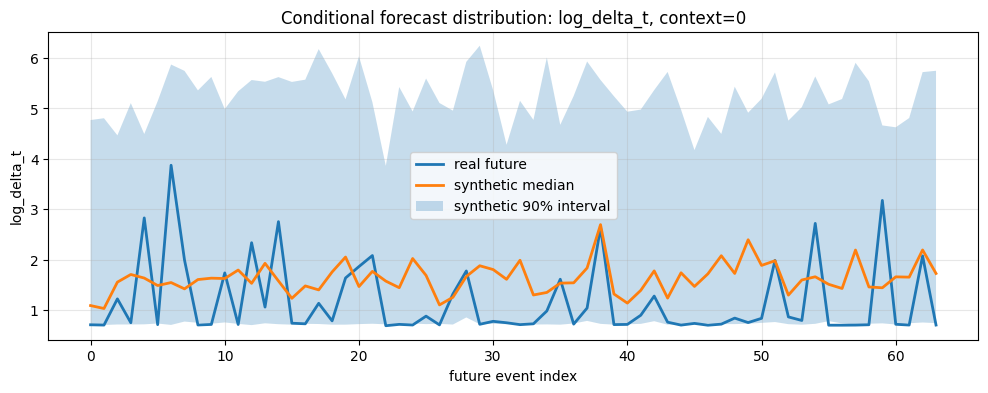

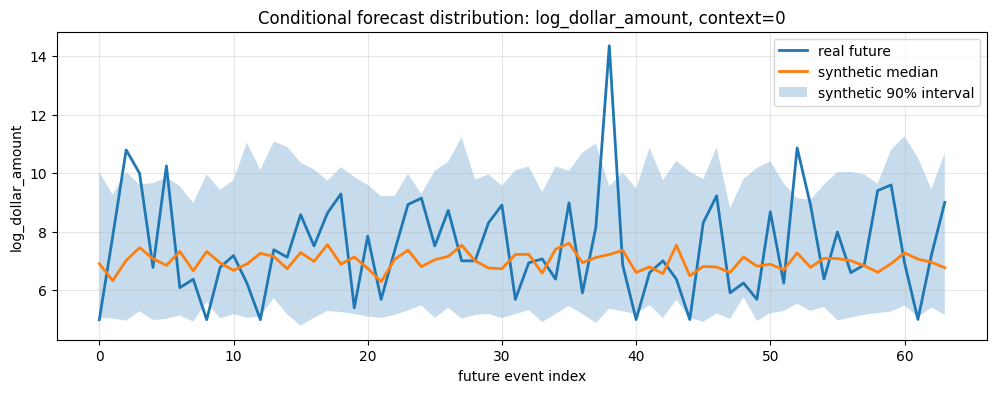

In [33]:
plot_conditional_forecast_band(
    context_id=0,
    channel_id=0,
    channel_name="log_delta_t"
)

plot_conditional_forecast_band(
    context_id=0,
    channel_id=1,
    channel_name="log_dollar_amount"
)

In [34]:
def interval_coverage(
    real_future: np.ndarray,
    syn_future: np.ndarray,
    channel_id: int,
    q_low: float = 0.05,
    q_high: float = 0.95
):
    """
    real_future shape: (N_CONTEXTS, PRED_LEN, INPUT_CHANNELS)
    syn_future shape:  (N_CONTEXTS, K_SAMPLES, PRED_LEN, INPUT_CHANNELS)
    """

    real_y = real_future[:, :, channel_id]

    low = np.quantile(
        syn_future[:, :, :, channel_id],
        q_low,
        axis=1
    )

    high = np.quantile(
        syn_future[:, :, :, channel_id],
        q_high,
        axis=1
    )

    inside = (real_y >= low) & (real_y <= high)

    return inside.mean()

CHANNEL_NAMES = [
    "log_delta_t",
    "log_dollar_amount"
]
for channel_id, channel_name in enumerate(CHANNEL_NAMES):
    cov = interval_coverage(
        real_future=real_future,
        syn_future=syn_future,
        channel_id=channel_id,
        q_low=0.05,
        q_high=0.95
    )

    print(f"{channel_name}: 90% interval coverage = {cov:.4f}")

log_delta_t: 90% interval coverage = 0.8086
log_dollar_amount: 90% interval coverage = 0.7874


In [35]:
def window_stats_array(x: np.ndarray) -> dict:
    """
    x shape: (n_windows, length, channels)

    channel 0 = log_delta_t
    channel 1 = log_dollar_amount
    """
    return {
        "mean_log_delta_t": x[:, :, 0].mean(axis=1),
        "p95_log_delta_t": np.quantile(x[:, :, 0], 0.95, axis=1),

        "mean_log_dollar_amount": x[:, :, 1].mean(axis=1),
        "p95_log_dollar_amount": np.quantile(x[:, :, 1], 0.95, axis=1),
        "max_log_dollar_amount": x[:, :, 1].max(axis=1),
    }


def window_stats_array_with_samples(x: np.ndarray) -> dict:
    """
    x shape: (N_CONTEXTS, K_SAMPLES, length, channels)

    Сначала считаем статистику каждого synthetic future sample,
    потом усредняем по K samples.

    Возвращает условное среднее:
        E_theta[S(future) | past]
    """
    n_contexts, k_samples, length, channels = x.shape

    flat_x = x.reshape(
        n_contexts * k_samples,
        length,
        channels
    )

    flat_stats = window_stats_array(flat_x)

    result = {}

    for key, value in flat_stats.items():
        value = value.reshape(n_contexts, k_samples)
        result[key] = value.mean(axis=1)

    return result


real_past_stats = window_stats_array(real_past)
real_future_stats = window_stats_array(real_future)

syn_future_mean_stats = window_stats_array_with_samples(syn_future)

In [36]:
from scipy.stats import spearmanr


def compare_conditional_mean_relation(
    past_stats: dict,
    real_future_stats: dict,
    syn_future_stats: dict,
    past_key: str,
    future_key: str
):
    real_corr = spearmanr(
        past_stats[past_key],
        real_future_stats[future_key]
    ).correlation

    syn_corr = spearmanr(
        past_stats[past_key],
        syn_future_stats[future_key]
    ).correlation

    print("=" * 80)
    print(f"{past_key} -> {future_key}")
    print(f"real Spearman: {real_corr:.4f}")
    print(f"syn  Spearman: {syn_corr:.4f}")
    print(f"abs diff:      {abs(real_corr - syn_corr):.4f}")


for past_key in real_past_stats.keys():
    for future_key in real_future_stats.keys():
        compare_conditional_mean_relation(
            past_stats=real_past_stats,
            real_future_stats=real_future_stats,
            syn_future_stats=syn_future_mean_stats,
            past_key=past_key,
            future_key=future_key
        )

mean_log_delta_t -> mean_log_delta_t
real Spearman: 0.2635
syn  Spearman: 0.8408
abs diff:      0.5773
mean_log_delta_t -> p95_log_delta_t
real Spearman: 0.3809
syn  Spearman: 0.8929
abs diff:      0.5120
mean_log_delta_t -> mean_log_dollar_amount
real Spearman: -0.3337
syn  Spearman: -0.8214
abs diff:      0.4877
mean_log_delta_t -> p95_log_dollar_amount
real Spearman: -0.3353
syn  Spearman: -0.5737
abs diff:      0.2384
mean_log_delta_t -> max_log_dollar_amount
real Spearman: -0.1981
syn  Spearman: -0.2204
abs diff:      0.0223
p95_log_delta_t -> mean_log_delta_t
real Spearman: 0.2338
syn  Spearman: 0.7407
abs diff:      0.5069
p95_log_delta_t -> p95_log_delta_t
real Spearman: 0.3348
syn  Spearman: 0.7906
abs diff:      0.4559
p95_log_delta_t -> mean_log_dollar_amount
real Spearman: -0.3683
syn  Spearman: -0.7046
abs diff:      0.3364
p95_log_delta_t -> p95_log_dollar_amount
real Spearman: -0.3504
syn  Spearman: -0.4406
abs diff:      0.0902
p95_log_delta_t -> max_log_dollar_amount
r

## <b>Executive Summary.</b>

**Data and setup.** A total of 236,066 liquidation events (BTC perp). Chronological 80/20 split: train - 188,852 events (2025-11-01 -> 2026-03-15), test - 47,214 events (2026-03-15 -> 2026-04-28). Window 256 = 192 known + 64 forecasted events. 2,947 training windows, 734 test windows. Model - 0.53M parameters.

**Marginal distribution quality (future-only, 64 events).**

| Channel | real mean/std | syn mean/std | KS | W1 |
|---|---|---|---|---|
| log_delta_t | 2.502 / 1.817 | 2.396 / 1.681 | **0.036** | 0.129 |
| log_dollar_amount | 7.179 / 1.765 | 7.151 / 1.597 | **0.086** | 0.138 |

Tail percentiles are reproduced closely: for `log_delta_t` p1/p50/p99 = 0.70 / 1.81 / 6.94 (real) vs 0.70 / 1.79 / 6.69 (syn); for `log_dollar_amount` - 4.32 / 6.93 / 12.00 vs 4.65 / 6.94 / 11.48. The model slightly underestimates variance (synthetic std is ~7-9% lower).

**Joint distribution of channels.** The cross-correlation between time and volume is reproduced almost exactly: Pearson −0.078 (real) vs −0.074 (syn), Spearman −0.078 vs −0.074.

**Predictive interval calibration (K=32 samples, 64 contexts).** 90% interval coverage: `log_delta_t` - **80.9%**, `log_dollar_amount` - **78.7%**. The intervals undercover the target level by ~9-11 pp, i.e. they are somewhat too narrow.

**Conditional dependence "past -> future".** When evaluated on a single sample, the Spearman discrepancy between real and syn is small (abs diff mostly 0.02-0.18). However, when averaged over multiple samples, the synthetic data noticeably **overestimates** the strength of conditional relationships: abs diff reaches 0.46-0.58 for the pairs `mean_log_delta_t -> mean/p95_log_delta_t`. This is the main weak spot.

**Conclusion.** The model reproduces the shape of marginal distributions and the cross-correlation of channels well (KS <=> 0.086). Main limitations: slightly underestimated variance, undercoverage of 90% intervals (~79-81%), and overstated conditional dependence of the forecast on context. For production, the priority is expanding/calibrating the predictive intervals and reducing the overstrengthened dependence on the past.